#Import

In [ ]:
from PIL import Image  # Import the Image module from Pillow
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

#MNIST classification using CNN model

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 53s 33ms/step - accuracy: 0.9484 - loss: 0.1675 - val_accuracy: 0.9805 - val_loss: 0.0680
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 47s 31ms/step - accuracy: 0.9842 - loss: 0.0503 - val_accuracy: 0.9819 - val_loss: 0.0644
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 79s 29ms/step - accuracy: 0.9889 - loss: 0.0345 - val_accuracy: 0.9870 - val_loss: 0.0428
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 45s 30ms/step - accuracy: 0.9917 - loss: 0.0268 - val_accuracy: 0.9887 - val_loss: 0.0414
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 81s 29ms/step - accuracy: 0.9934 - loss: 0.0200 - val_accuracy: 0.9887 - val_loss: 0.0439
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


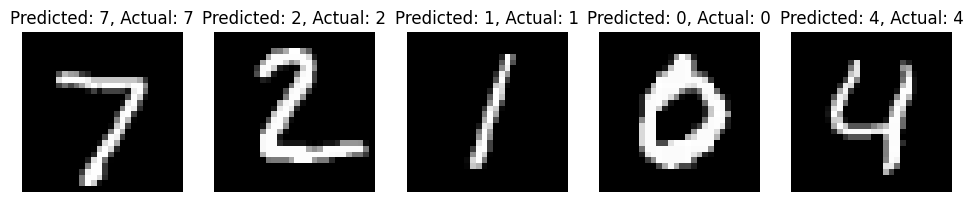

In [ ]:
# Import Libraries
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load the MNIST Dataset
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preprocess the Data
x_train = x_train.reshape((60000, 28, 28, 1)).astype('float32') / 255.0
x_test = x_test.reshape((10000, 28, 28, 1)).astype('float32') / 255.0

# Build a Simple CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0-9
])

# Compile the Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the Model
model.fit(x_train, y_train, epochs=5, validation_split=0.2)

# Make Predictions on Test Set
predictions = model.predict(x_test)

# Display Sample Predictions
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {tf.argmax(predictions[i]).numpy()}, Actual: {y_test[i]}")
    plt.axis('off')
plt.show()


#Object Detection

In [ ]:
# Set up the environment
!git clone https://github.com/ultralytics/yolov5  # Clone the YOLOv5 repo
%cd yolov5
!pip install -r requirements.txt  # Install requirements

# Import libraries
import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load a pre-trained YOLOv5 model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')  # Load YOLOv5s model (small)


Cloning into 'yolov5'...
remote: Enumerating objects: 18806, done.
remote: Counting objects: 100% (358/358), done.
remote: Compressing objects: 100% (210/210), done.
remote: Total 18806 (delta 298), reused 148 (delta 148), pack-reused 18448 (from 2)
Receiving objects: 100% (18806/18806), 17.72 MiB | 16.03 MiB/s, done.
Resolving deltas: 100% (12816/12816), done.
/content/yolov5/yolov5
YOLOv5 🚀 2026-10-29 Python-3.13.18 torch-2.11.0+cpu CPU



Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


100%|██████████| 14.1M/14.1M [00:00<00:00, 104MB/s] 

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


In [ ]:
!pip install requests


In [ ]:
import requests

# Define the URL of the image
url = 'https://github.com/ultralytics/yolov5/releases/download/v1.0/zidane.jpg'

# Send a GET request to the URL
response = requests.get(url)

# Open a file in binary write mode
with open('zidane.jpg', 'wb') as f:
    f.write(response.content)

print("Image downloaded successfully!")


Image downloaded successfully!


YOLOv5 🚀 2026-10-29 Python-3.13.18 torch-2.11.0+cpu CPU

Fusing layers... 


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


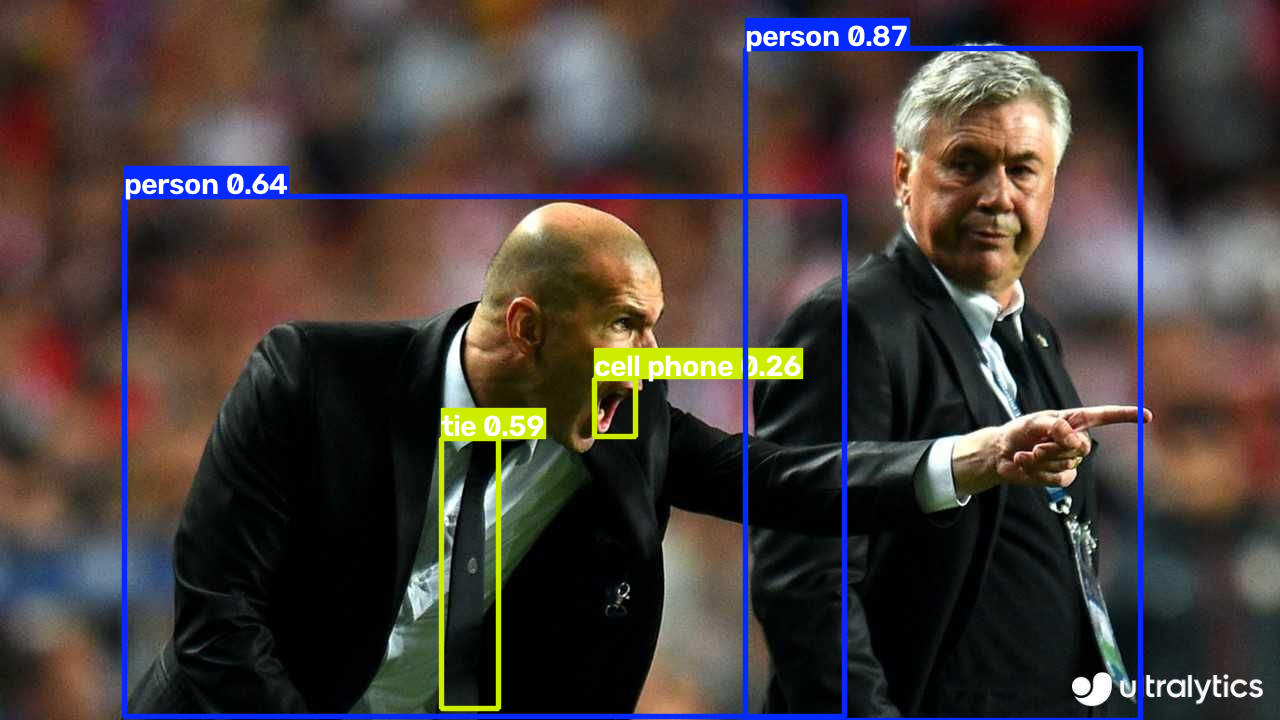

In [ ]:
import torch

# Load the YOLOv5 model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')

# Load the image
img = 'zidane.jpg'  # path to your image

# Perform inference
results = model(img)

# Show results
results.show()  # This will display the image with detections


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from PIL import Image
image = Image.open('zidane.jpg')


Mounted at /content/drive


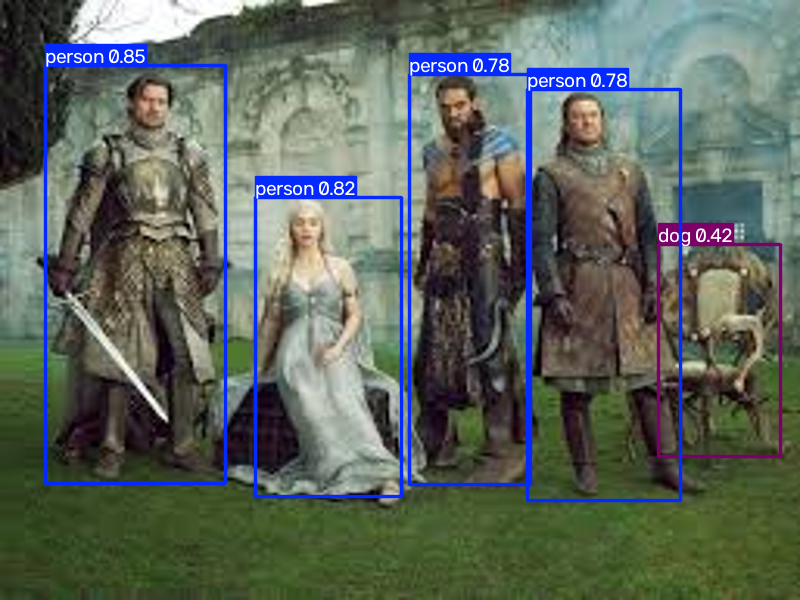

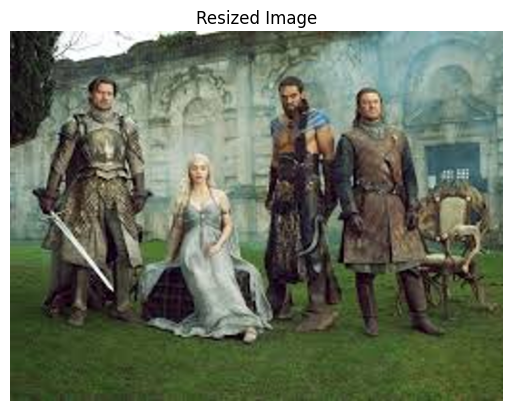

In [ ]:

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


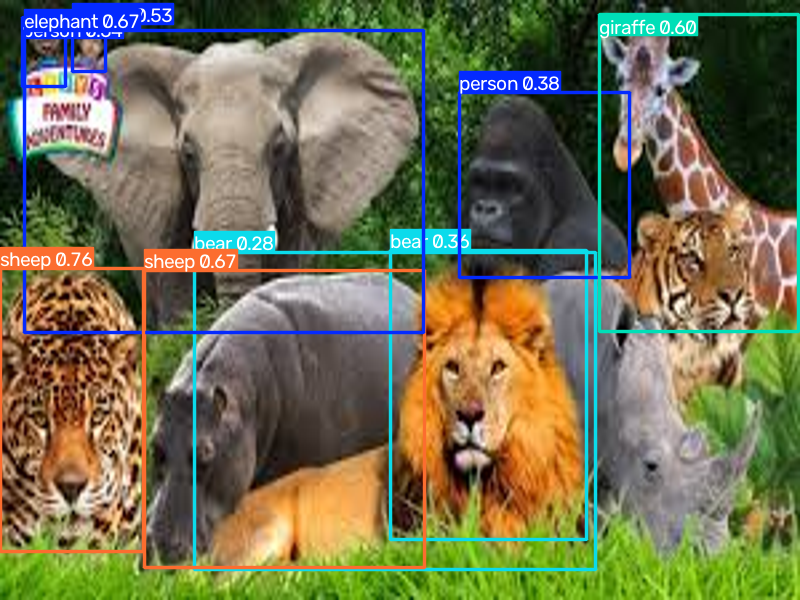

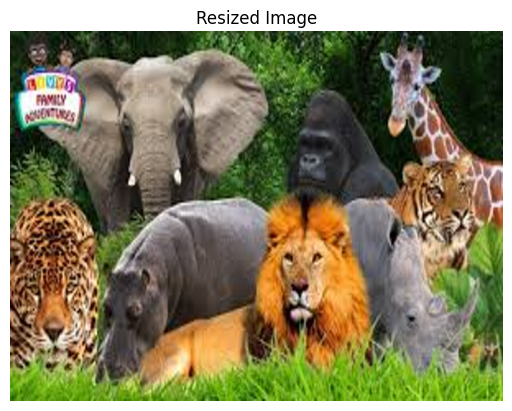

In [ ]:
from PIL import Image
image = Image.open('/animals.jpeg')
# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


#Segmentation

In [ ]:
!pip install tensorflow tensorflow-datasets matplotlib numpy


#HomeWork2

Run this cell first to load the required dataset

In [ ]:
# Load the MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X, y = mnist['data'], mnist['target']

# Preprocess the Data
X = X / 255.0  # Normalize pixel values to [0, 1]
y = y.astype(np.uint8)  # Convert labels to integers

#  Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data for SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


##Part1 : In this section, we want to classify the MNIST dataset using Random Forest, Logistic Regression, and Neural Networks. We will print the accuracy for each model. The code for Random Forest will serve as an example, and you should complete the code for Logistic Regression and Neural Networks accordingly.

In [ ]:
# Train Different Classifiers

#  1. Random Forest
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
)

rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Accuracy of Random Forest: {accuracy_rf:.4f}")

Accuracy of Random Forest: 0.9675


In [ ]:
# 2. Logistic Regression
lr_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

lr_classifier.fit(X_train_scaled, y_train)
y_pred_lr = lr_classifier.predict(X_test_scaled)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Accuracy of Logistic Regression: {accuracy_lr:.4f}")

Accuracy of Logistic Regression: 0.9154


In [ ]:
# 3. Neural Network
nn_classifier = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=200,
    random_state=42,
)
nn_classifier.fit(X_train_scaled, y_train)
y_pred_nn = nn_classifier.predict(X_test_scaled)
accuracy_nn = accuracy_score(y_test, y_pred_nn)

print(f"Accuracy of Neural Network: {accuracy_nn:.4f}")

Accuracy of Neural Network: 0.9712


In [ ]:
# Step 6: Print accuracy results
print(f"Logistic Regression Accuracy: {accuracy_lr * 100:.2f}%")
print(f"Random Forest Accuracy: {accuracy_rf * 100:.2f}%")
print(f"MLP Accuracy: {accuracy_nn * 100:.2f}%")

Logistic Regression Accuracy: 91.54%
Random Forest Accuracy: 96.75%
MLP Accuracy: 97.12%


## Part2: take a photo of yourself, upload it to the jupyter notebook and detect your face using Yolo model

image 1/1: 2587x2242 1 person, 1 cup, 1 tv, 1 laptop, 1 mouse, 2 keyboards
Speed: 160.2ms pre-process, 422.8ms inference, 8.0ms NMS per image at shape (1, 3, 640, 576)


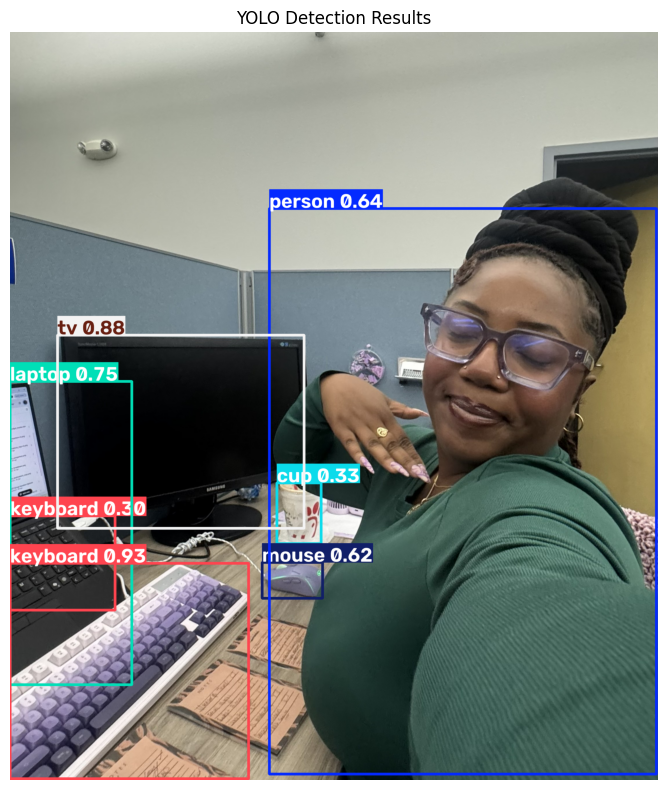

In [ ]:
# your code here
from PIL import Image
import matplotlib.pyplot as plt

# Load your photo
img_path = "/content/IMG_5703.jpg"
photo = Image.open(img_path).convert("RGB")

# Perform inference using the previously loaded YOLO model
results = yolo_model(photo)

# Print detection results
results.print()

# Display the photo with detection boxes
annotated_image = results.render()[0]

plt.figure(figsize=(10, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("YOLO Detection Results")
plt.tight_layout()
plt.show()